# IBM Employee Attrition Analysis

**Goal:** find where and why employees leave, and suggest retention actions.

**Dataset:** IBM HR Analytics Employee Attrition & Performance (Kaggle), 1,470 employees, 35 columns.

**Tools:** Python (Pandas, Matplotlib), SQL (SQLite), Power BI (dashboard built separately).

**Note:** this notebook runs in Google Colab. Upload the dataset CSV when the first cell asks for it.

## 1. Load the data

In [4]:
from google.colab import files
uploaded = files.upload()

Saving WA_Fn-UseC_-HR-Employee-Attrition.csv to WA_Fn-UseC_-HR-Employee-Attrition (1).csv


## 2. Inspect and clean the data

In [5]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
print(df.shape)

df.info()
print(df.isnull().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicate rows")

df = df.drop(columns=["EmployeeCount", "Over18", "StandardHours", "EmployeeNumber"])
df["AttritionFlag"] = (df["Attrition"] == "Yes").astype(int)

print("Attrition rate: {:.1%}".format(df["AttritionFlag"].mean()))
print(df.groupby("Department")["AttritionFlag"].mean().sort_values(ascending=False))
print(df.groupby("OverTime")["AttritionFlag"].mean())


(1470, 35)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel     

## 3. Exploratory data analysis (EDA)

AgeBand
18-25    0.358
26-35    0.191
36-45    0.092
46-55    0.115
56+      0.170
Name: AttritionFlag, dtype: float64 

IncomeBand
Low         0.293
Mid-Low     0.142
Mid-High    0.106
High        0.103
Name: AttritionFlag, dtype: float64 

JobRole
Healthcare Representative    0.069
Human Resources              0.231
Laboratory Technician        0.239
Manager                      0.049
Manufacturing Director       0.069
Research Director            0.025
Research Scientist           0.161
Sales Executive              0.175
Sales Representative         0.398
Name: AttritionFlag, dtype: float64 

JobSatisfaction
1    0.228
2    0.164
3    0.165
4    0.113
Name: AttritionFlag, dtype: float64 

YearsSinceLastPromotion
0     0.189
1     0.137
2     0.170
3     0.173
4     0.082
5     0.044
6     0.188
7     0.211
8     0.000
9     0.235
10    0.167
11    0.083
12    0.000
13    0.200
14    0.111
15    0.231
Name: AttritionFlag, dtype: float64 

BusinessTravel
Non-Travel           0.080
Tra

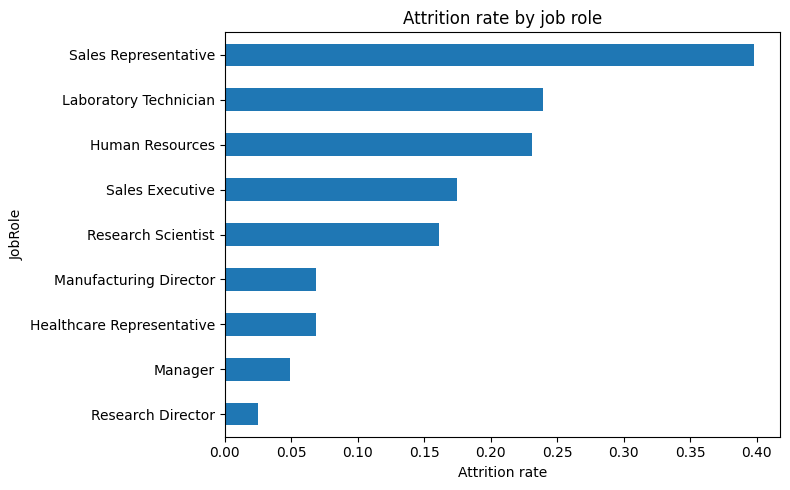

In [6]:
import matplotlib.pyplot as plt

# Age and income bands
df["AgeBand"] = pd.cut(df["Age"], [17, 25, 35, 45, 55, 70],
                       labels=["18-25", "26-35", "36-45", "46-55", "56+"])
df["IncomeBand"] = pd.qcut(df["MonthlyIncome"], 4,
                           labels=["Low", "Mid-Low", "Mid-High", "High"])

for col in ["AgeBand", "IncomeBand", "JobRole", "JobSatisfaction",
            "YearsSinceLastPromotion", "BusinessTravel"]:
    print(df.groupby(col, observed=True)["AttritionFlag"].mean().round(3), "\n")

# Manager and tenure hotspots
print(df.groupby("YearsWithCurrManager")["AttritionFlag"].agg(["mean", "count"]).round(3))

# Chart: attrition by job role
role = df.groupby("JobRole")["AttritionFlag"].mean().sort_values()
role.plot(kind="barh", figsize=(8, 5), title="Attrition rate by job role")
plt.xlabel("Attrition rate")
plt.tight_layout()
plt.show()

## 4. SQL analysis

In [7]:
import sqlite3

d = df.copy()
d["AgeBand"] = d["AgeBand"].astype(str)
d["IncomeBand"] = d["IncomeBand"].astype(str)

conn = sqlite3.connect(":memory:")
d.to_sql("employees", conn, index=False, if_exists="replace")

# Query 1: attrition by department and overtime
q1 = """
SELECT Department, OverTime,
       COUNT(*) AS headcount,
       SUM(AttritionFlag) AS leavers,
       ROUND(100.0 * SUM(AttritionFlag) / COUNT(*), 1) AS attrition_pct
FROM employees
GROUP BY Department, OverTime
ORDER BY attrition_pct DESC;
"""
print(pd.read_sql(q1, conn))

# Query 2: highest-risk segment (low income + overtime + frequent travel)
q2 = """
SELECT COUNT(*) AS headcount,
       ROUND(100.0 * SUM(AttritionFlag) / COUNT(*), 1) AS attrition_pct
FROM employees
WHERE IncomeBand = 'Low' AND OverTime = 'Yes' AND BusinessTravel = 'Travel_Frequently';
"""
print(pd.read_sql(q2, conn))

# Query 3: job roles ranked by attrition, with headcount
q3 = """
SELECT JobRole, COUNT(*) AS headcount,
       ROUND(100.0 * SUM(AttritionFlag) / COUNT(*), 1) AS attrition_pct,
       ROUND(AVG(MonthlyIncome), 0) AS avg_income
FROM employees
GROUP BY JobRole
ORDER BY attrition_pct DESC;
"""
print(pd.read_sql(q3, conn))

               Department OverTime  headcount  leavers  attrition_pct
0                   Sales      Yes        128       48           37.5
1         Human Resources      Yes         17        5           29.4
2  Research & Development      Yes        271       74           27.3
3         Human Resources       No         46        7           15.2
4                   Sales       No        318       44           13.8
5  Research & Development       No        690       59            8.6
   headcount  attrition_pct
0         28           71.4
                     JobRole  headcount  attrition_pct  avg_income
0       Sales Representative         83           39.8      2626.0
1      Laboratory Technician        259           23.9      3237.0
2            Human Resources         52           23.1      4236.0
3            Sales Executive        326           17.5      6924.0
4         Research Scientist        292           16.1      3240.0
5     Manufacturing Director        145            6

## 5. Key findings

- Overall attrition rate is **16.1%** (237 of 1,470 employees).
- Employees working overtime leave at **30.5%**, versus **10.4%** without overtime.
- Employees aged 18-25 leave at **35.8%**, versus 9.2% for ages 36-45.
- Sales Representatives have the highest role attrition at **39.8%** and the lowest average income of any role.
- The lowest income band leaves at **29.3%**, versus about 10% for the top two bands.
- Employees with 0 years under their current manager leave at **32.3%**.
- A small segment of 28 employees (low income, overtime, frequent travel) has 71.4% attrition.

**Limitation:** these are associations, not proven causes. Age, pay, role and overtime overlap.

**Recommendations:** review workload in overtime-heavy roles, run a pay review for the lowest income band, and strengthen first-year onboarding and manager check-ins.

## 6. Export cleaned data for Power BI

In [8]:
from google.colab import files
df.to_csv("attrition_clean.csv", index=False)
files.download("attrition_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>